# stage 1: raw pixels and softmax classification

## central question

how well can a softmax classifier recognize hand signs directly from raw
pixels, and what does the classifier look at?

in this stage, each image is represented by its original 784 pixel values.

the classifier will be multinomial logistic regression, which acts as a
softmax classifier for the 24 hand-sign classes.

the main goals are:

- explore the hand-sign images
- choose the regularization parameter C using validation data
- measure final performance on the official test set
- visualize the learned class weights
- analyze the most common class confusions

## data loading and initial inspection

before training any model, i will inspect the dataset and verify its structure.

the dataset contains 28 by 28 grayscale images.

each image is stored as one row with:

- one label
- 784 pixel values

the labels represent the letters A to Z, except J and Z because these signs
require motion.

at this stage, i will only inspect the data.

the official test set, will not be used for model selection or tuning.

In [1]:
# import pandas for reading csv files
import pandas as pd

# import numpy for numerical operations
import numpy as np

# save the training file path
train_path = "../data/raw/sign_mnist_train.csv"

# save the test file path
test_path = "../data/raw/sign_mnist_test.csv"

# read the training csv file
train_df = pd.read_csv(train_path)

# read the test csv file
test_df = pd.read_csv(test_path)

# create a list with all pixel column names, without the label column
pixel_columns = [ column for column in train_df.columns if column != "label"]
    
# print the training data shape
print("training shape:", train_df.shape)

# print the test data shape
print("test shape:", test_df.shape)

# print the number of pixel columns
print("number of pixel features:", len(pixel_columns))

# get the unique training labels
unique_labels = np.sort(  train_df["label"].unique() )
    
# print the training labels
print("training labels:", unique_labels)

# print the number of classes
print("number of classes:", len(unique_labels))

# find the minimum pixel value
minimum_pixel = train_df[pixel_columns].to_numpy().min()

# find the maximum pixel value
maximum_pixel = train_df[pixel_columns].to_numpy().max()

# print the minimum pixel value
print("minimum pixel value:", minimum_pixel)

# print the maximum pixel value
print("maximum pixel value:", maximum_pixel)

training shape: (27455, 785)
test shape: (7172, 785)
number of pixel features: 784
training labels: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]
number of classes: 24
minimum pixel value: 0
maximum pixel value: 255


## visual inspection of the hand signs

before training the classifier, i will inspect example images from the
different classes.

the purpose is to understand what the raw pixel inputs look like, and to identify
letter pairs, that may be visually similar.

this is important, because the stage 1 classifier will operate directly on the
784 pixel values, without learning more advanced image features.

### prediction before modeling

i expect some visually similar hand signs, to be more difficult to distinguish,
using raw pixels and a linear softmax classifier.

after inspecting the images, i will record the letter pairs, that i expect to be
confused, and later compare this prediction, with the confusion matrix.

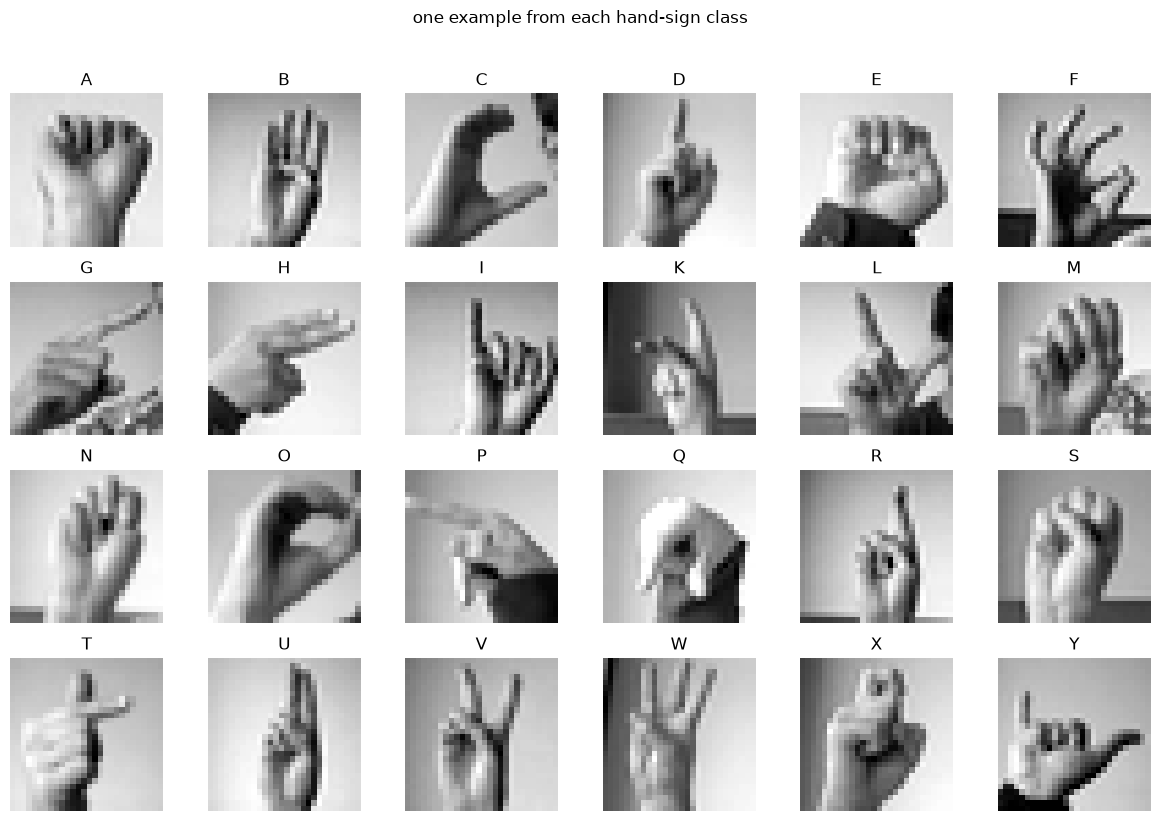

In [2]:
# import matplotlib for displaying images
import matplotlib.pyplot as plt

# create a function that converts a label to a letter
def label_to_letter(label):
    return chr(ord("A") + int(label))

# create a figure, with four rows and six columns
fig, axes = plt.subplots( 4 ,  6 ,  figsize=(12, 8) )

# flatten the axes array, for easier access
axes = axes.flatten()

# go through every class label
for axis, label in zip(axes, unique_labels):

    # find the first row, with the current label
    row_index = train_df.index[ train_df["label"] == label ] [0]
    
    # get the pixel values from that row
    image_pixels = train_df.loc [ row_index , pixel_columns].to_numpy()
        
    # reshape the 784 pixel values, into a 28 by 28 image
    image = image_pixels.reshape(28,28)

    # show the grayscale image
    axis.imshow(image, cmap="gray")

    # write the corresponding letter, above the image
    axis.set_title( label_to_letter(label) )

    # hide the axis values
    axis.axis("off")

# write the figure title
fig.suptitle( "one example from each hand-sign class",y=1.02)

# fix the spacing
plt.tight_layout()

# save the figure
plt.savefig( "../results/figures/stage1_class_examples.png" , dpi=200,  bbox_inches="tight")
   
# show the figure
plt.show()

### expected confusions before modeling

after visually inspecting one example from each class, i expect some letter
pairs to be more difficult for a linear softmax classifier on raw pixels.

the pairs i expect to be confused fr exampe are:

- M and N
- U and V
- R and U
- A and S
- G and H

these pairs have similar overall hand shapes, while some of their differences
depend on relatively small changes in finger position.

because the stage 1 classifier works directly on raw pixel values, even small
changes in hand position or orientation may also affect the representation.

later, i will compare these predictions with the confusion matrix produced by
the trained classifier.

## train-validation split

the official training set will be divided into a training set and a validation set.

the validation set will be used for model selection, including choosing the
regularization parameter C.

the official test set will not be used during model selection.

the same train-validation split will also be used in the later stages so that
the results are directly comparable.

i will use stratification so that the class proportions remain more or less
the same in the training and validation sets.

i will also use a fixed random seed so that the split is reproducible.

In [3]:
# import the train-validation split function
from sklearn.model_selection import train_test_split

# create the full training feature matrix
x_full = train_df[pixel_columns].to_numpy()

# create the full training label vector
y_full = train_df["label"].to_numpy()

# create the official test feature matrix
x_test = test_df[pixel_columns].to_numpy()

# create the official test label vector
y_test = test_df["label"].to_numpy()

# split the official training data, into train and validation
x_train, x_val, y_train, y_val = train_test_split( x_full , y_full , test_size=0.2 , random_state=42 , stratify=y_full )

# convert the training pixels to float values, and scale them to 0-1
x_train = x_train.astype("float32") / 255.0

# convert the validation pixels to float values, and scale them to 0-1
x_val = x_val.astype("float32") / 255.0

# convert the test pixels to float values, and scale them to 0-1
x_test = x_test.astype("float32") / 255.0

# print the training shape
print("training shape:", x_train.shape)

# print the validation shape
print("validation shape:", x_val.shape)

# print the test shape
print("test shape:", x_test.shape)

# print the training pixel range
print("training pixel range:", x_train.min(), "to", x_train.max())

training shape: (21964, 784)
validation shape: (5491, 784)
test shape: (7172, 784)
training pixel range: 0.0 to 1.0


## experiment 1: choosing the regularization parameter C

### question

which value of C gives the best validation accuracy for the softmax classifier
on raw pixel features?

the softmax classifier uses L2 regularization.

the parameter C controls the strength of this regularization:

- a small C means stronger regularization
- a large C means weaker regularization

strong regularization may make the model too simple and cause underfitting.

very weak regularization may allow the model to fit the training data too
closely and generalize less good.

### prediction

i expect an balanced value of C to perform best.

i expect very small values of C to reduce validation accuracy because the model
will be too strongly regularized.

i do not expect very large values of C to provide a large improvement because
the model may begin to overfit.

i will test several values of C using only the validation set.

the official test set will not be used in this experiment.

In [4]:
# import the softmax classifier
from sklearn.linear_model import LogisticRegression

# import the accuracy function
from sklearn.metrics import accuracy_score

# choose the 7, c values ,to test

c_values = [ 0.001 , 0.01 , 0.1 , 1.0 , 10.0 , 100.0 , 1000.0 ]

# create an empty list, for the results
c_results = []

# go through every c value
for c_value in c_values:

    # create the softmax classifier, with the current c value
    softmax_model = LogisticRegression( C=c_value , solver="lbfgs" , max_iter=3000 , random_state=42 )

    # train the model, on the training data
    softmax_model.fit( x_train , y_train )

    # predict the validation labels
    y_val_pred = softmax_model.predict( x_val )

    # calculate the validation accuracy
    val_accuracy = accuracy_score( y_val , y_val_pred )

    # count the validation errors
    val_errors = np.sum( y_val_pred != y_val )

    # save the current result
    c_results.append( [ c_value , val_accuracy , val_errors ] )

    # print the current result
    print( "C:" , c_value , "accuracy:" , val_accuracy , "errors:" , val_errors )

C: 0.001 accuracy: 0.6166454197778183 errors: 2105
C: 0.01 accuracy: 0.8328173374613003 errors: 918
C: 0.1 accuracy: 0.9834274266982335 errors: 91
C: 1.0 accuracy: 0.9996357676197414 errors: 2
C: 10.0 accuracy: 0.9998178838098707 errors: 1
C: 100.0 accuracy: 0.9983609542888363 errors: 9
C: 1000.0 accuracy: 0.998178838098707 errors: 10


### C validation results

the validation accuracy changed substantially as C increased.

the results were:

- C = 0.001: 61.66% accuracy, 2105 errors
- C = 0.01: 83.28% accuracy, 918 errors
- C = 0.1: 98.34% accuracy, 91 errors
- C = 1: 99.96% accuracy, 2 errors
- C = 10: 99.98% accuracy, 1 error
- C = 100: 99.84% accuracy, 9 errors
- C = 1000: 99.82% accuracy, 10 errors

the best validation result was obtained with C = 10.

very small values of C caused a large decrease in validation accuracy, which is
consistent with the model being too strongly regularized.

as C increased, the validation accuracy improved until C = 10.

increasing C further to 100 and 1000 did not improve performance and slightly
reduced the validation accuracy.

therefore, my prediction that an intermediate value of C would perform best was
supported by the experiment.

i will use C = 10 as the selected regularization parameter for the final stage 1
softmax classifier.

## validation accuracy as a function of C

the next graph shows how the validation accuracy changes as the
regularization parameter C changes.

because the tested C values range from 0.001 to 1000, i will use a logarithmic
horizontal axis.

this makes it easier to compare values that change by several orders of
magnitude.

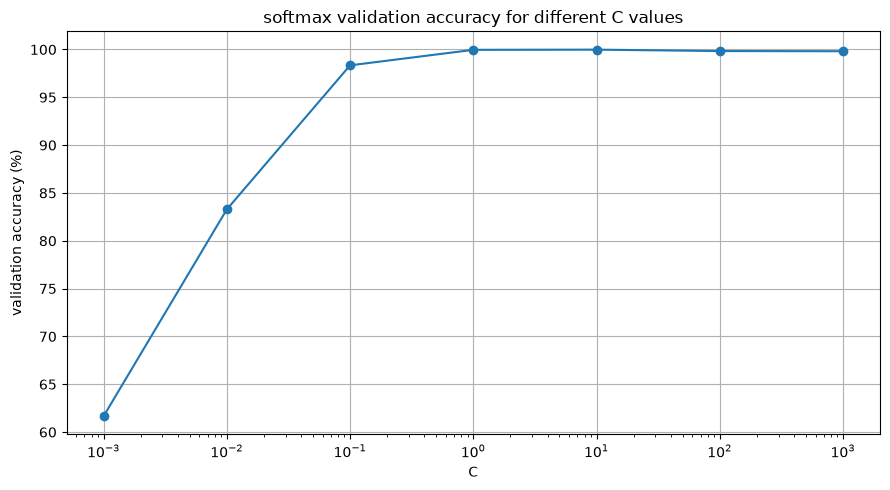

In [5]:
# convert the results, into a numpy array
c_results_array = np.array(c_results)

# get the tested c values
tested_c_values = c_results_array[:,0]

# get the validation accuracies, as percentages
validation_accuracies = c_results_array[:,1] * 100

# create a new figure
plt.figure( figsize=(9,5) )

# draw the validation accuracy curve
plt.plot( tested_c_values , validation_accuracies , marker="o" )

# use a logarithmic scale, for the c values
plt.xscale("log")

# write the horizontal axis name
plt.xlabel("C")

# write the vertical axis name
plt.ylabel("validation accuracy (%)")

# write the graph title
plt.title("softmax validation accuracy for different C values")

# add a grid
plt.grid(True)

# fix the spacing
plt.tight_layout()

# save the graph
plt.savefig( "../results/figures/stage1_c_validation_accuracy.png" , dpi=200 , bbox_inches="tight" )

# show the graph
plt.show()

### interpretation of the C validation curve

the graph shows that validation accuracy improves strongly as C increases
from very small values.

small values of C apply strong regularization, and the model performs poorly
because it is too constrained.

the accuracy becomes almost perfect around C = 1 and C = 10.

the best validation result is obtained with C = 10.

increasing C beyond 10 does not improve validation accuracy and causes a small
decrease.

therefore, C = 10 is selected for the final stage 1 softmax classifier.

## stage 1 self-check

### 1. what do large positive and negative class weights mean?

for each class, the softmax classifier learns one weight for each of the
784 input pixels.

for class c, the score is more or less:

z_c = w_c^T x + b_c

the weight vector w_c contains 784 values, so it can be reshaped into a
28 by 28 image.

a large positive weight means that a high pixel value in that location
increases the score for that class.

a large negative weight means that a high pixel value in that location
decreases the score for that class.

a weight close to zero means that the pixel has relatively little influence
on the score for that class.

therefore, reshaping the weights into an image can help show which image
areas the classifier uses, as evidence for or against a specific letter.


### 2. why is a small image, shift a large change for a raw-pixel classifier?

the raw-pixel classifier treats every pixel location as a separate feature.

for example, pixel 100 and pixel 102 are two different input features.

if the hand moves by two pixels, many of the pixel values move to different
positions in the 784-dimensional input vector.

the hand maybe look almost identical to a person, but the numerical input vector
can change strongly.

the softmax classifier  not automatically know that nearby pixel positions
represent the same visual structure.

therefore, a classifier that works directly on raw pixels, can be sensitive to
small translations of the hand.


### 3. why can a random validation split give optimistic accuracy?

the dataset was created from a much smaller collection of original hand
photographs.

many additional images were produced by applying small transformations such as
rotation, brightness changes, contrast changes, filters and pixelation.

because of this, different rows in the dataset can be near-copies that came
from the same original photograph.

with a random train-validation split, a transformed version of one original
photo may appear in the training set, while another very similar version appears
in the validation set.

this can make the validation task easier because the model has already seen a
very similar image during training.

therefore, random validation accuracy may be higher than accuracy on the
official test set.

## final stage 1 softmax model

after comparing several values of C using the validation set, i selected:

C = 10

this value achieved the highest validation accuracy.

i will now train the final stage 1 softmax classifier using the same training
data and C = 10.

the official test set has not been used for model selection.

it will now be used to measure the final stage 1 test accuracy.

### prediction

because the validation accuracy was almost perfect, i expect the test accuracy
to also be high.

however, i expect the test accuracy to be lower than the validation accuracy.

the dataset contains many transformed near-copies of original images, so the
random validation split may be easier than the official test set.

In [6]:
# create the final stage 1 softmax classifier
final_softmax = LogisticRegression( C=10.0 , solver="lbfgs" , max_iter=3000 , random_state=42 )

# train the final model, on the training data
final_softmax.fit( x_train , y_train )

# predict the validation labels
y_val_pred_final = final_softmax.predict( x_val )

# predict the official test labels
y_test_pred_final = final_softmax.predict( x_test )

# calculate the validation accuracy
final_val_accuracy = accuracy_score( y_val , y_val_pred_final )

# calculate the test accuracy
final_test_accuracy = accuracy_score( y_test , y_test_pred_final )

# count the validation errors
final_val_errors = np.sum( y_val_pred_final != y_val )

# count the test errors
final_test_errors = np.sum( y_test_pred_final != y_test )

# print the selected c value
print( "selected C:" , 10.0 )

# print the validation result
print( "validation accuracy:" , final_val_accuracy , "errors:" , final_val_errors )

# print the test result
print( "test accuracy:" , final_test_accuracy , "errors:" , final_test_errors )

selected C: 10.0
validation accuracy: 0.9998178838098707 errors: 1
test accuracy: 0.6926938092582264 errors: 2204


### final stage 1 accuracy result

the selected model used C = 10.

the final results were:

- validation accuracy: 99.98%
- validation errors: 1
- test accuracy: 69.27%
- test errors: 2204

the validation-test gap is very large.

the validation accuracy is about 30.71 percentage points higher than the
official test accuracy.

this supports my prediction that the random validation split would give an
optimistic estimate of performance.

the dataset contains many transformed near-copies of a smaller set of original
photographs.

therefore, very similar images can appear in both the training and validation
sets.

the official test set appears to be substantially more difficult for the
raw-pixel softmax classifier.

this result shows why validation accuracy alone is not enough to estimate the
real generalization performance of this model.

## softmax weight images

the softmax classifier learns one weight for every input pixel and every class.

each class therefore has 784 learned weights.

because the original images are 28 by 28 pixels, the 784 weights can also be
reshaped into a 28 by 28 image.

this visualization helps show which pixel locations provide positive or
negative evidence for each class.

i will inspect the learned weights for five example letters:

- A
- M
- N
- U
- V

some of these letters were also predicted to be visually similar before
training the model.

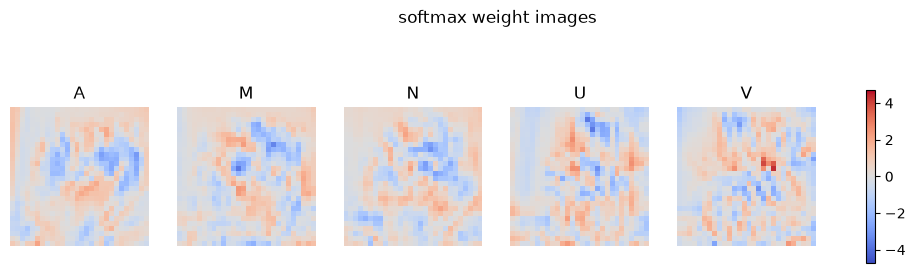

In [7]:
# choose five labels to inspect
weight_labels = [ 0 , 12 , 13 , 20 , 21 ]

# find the largest absolute weight, across all classes
max_weight = np.max( np.abs(final_softmax.coef_) )

# create a figure, with one row and five columns
fig, axes = plt.subplots( 1 , 5 , figsize=(13,3) )

# go through every selected label
for axis, label in zip(axes, weight_labels):

    # find the model row, for the current label
    class_index = np.where( final_softmax.classes_ == label )[0][0]

    # get the 784 learned weights, for the current class
    class_weights = final_softmax.coef_[class_index]

    # reshape the weights, into a 28 by 28 image
    weight_image = class_weights.reshape(28,28)

    # show the weight image, with the same color scale
    image = axis.imshow( weight_image , cmap="coolwarm" , vmin=-max_weight , vmax=max_weight )

    # write the corresponding letter, above the image
    axis.set_title( label_to_letter(label) )

    # hide the axis values
    axis.axis("off")

# write the figure title
fig.suptitle( "softmax weight images" , y=1.05 )

# add one shared color scale
fig.colorbar( image , ax=axes , shrink=0.75 )

# save the figure
plt.savefig( "../results/figures/stage1_softmax_weight_images.png" , dpi=200 , bbox_inches="tight" )

# show the figure
plt.show()

### interpretation of the softmax weight images

the weight images show which pixel locations provide positive or negative
evidence for each class.

red regions correspond to positive weights.

a high pixel value in these regions increases the score for the corresponding
letter.

blue regions correspond to negative weights.

a high pixel value in these regions decreases the score for the corresponding
letter.

the weight images do not look exactly like the original hand signs because
they represent discriminative evidence rather than reconstructed images.

the patterns for visually similar letters such as M and N, and U and V, share
some similarities but also contain different positive and negative regions.

this suggests that the classifier uses specific spatial pixel patterns to
distinguish between similar hand shapes.

because the model works directly on fixed pixel locations, these learned
patterns may also explain why the raw-pixel classifier is sensitive to changes
in hand position.

## confusion matrix on the official test set

the final stage 1 model made 2204 errors on the official test set.

i will now analyze these predictions using a confusion matrix.

the confusion matrix shows how often each true letter was predicted as each
possible letter.

the diagonal represents correct predictions.

values outside the diagonal represent classification errors.

this analysis will help identify which letter pairs are most difficult for the
raw-pixel softmax classifier.

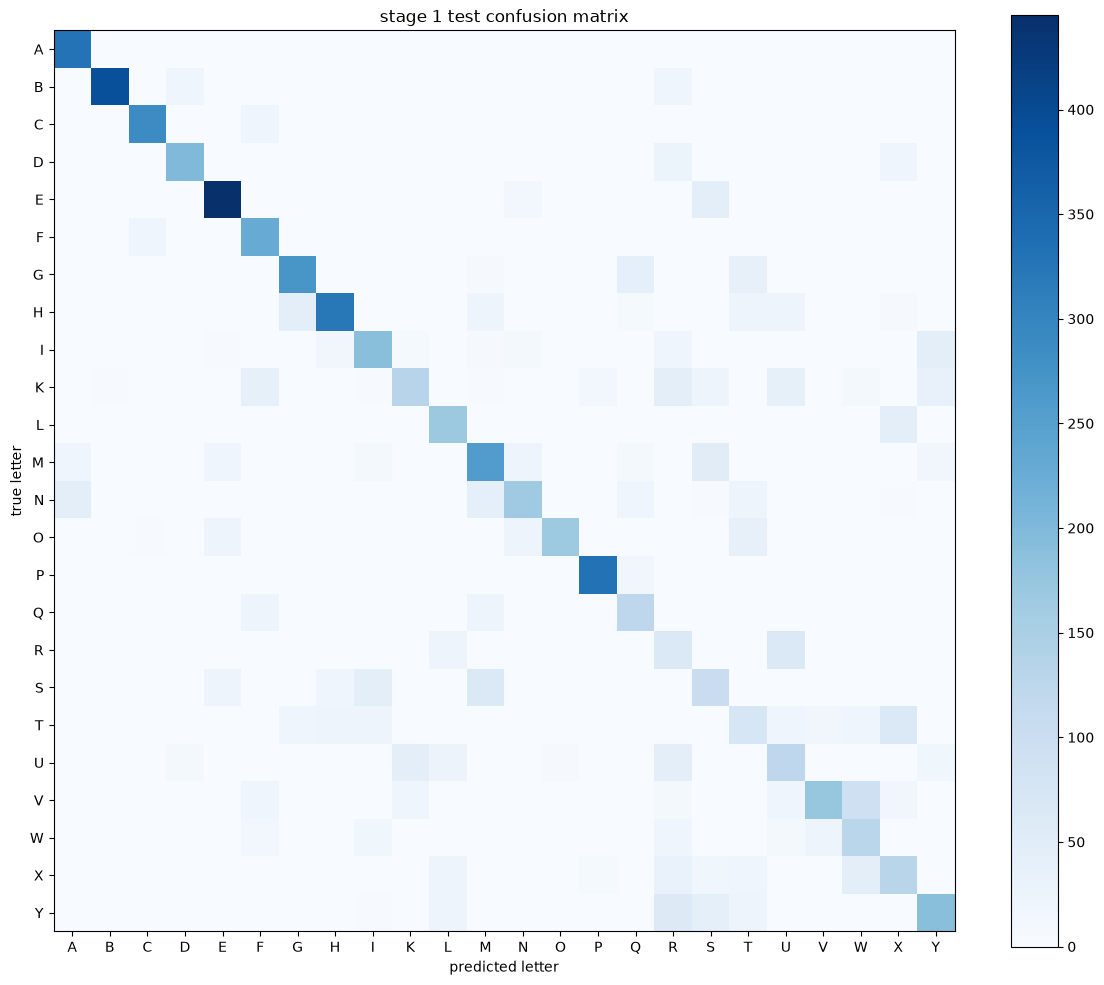

In [8]:
# import the confusion matrix function
from sklearn.metrics import confusion_matrix

# create the confusion matrix
test_confusion_matrix = confusion_matrix( y_test , y_test_pred_final , labels=unique_labels )

# create the letter names
class_letters = [ label_to_letter(label) for label in unique_labels ]

# create a new figure
plt.figure( figsize=(12,10) )

# show the confusion matrix
plt.imshow( test_confusion_matrix , cmap="Blues" )

# write the graph title
plt.title("stage 1 test confusion matrix")

# write the horizontal axis name
plt.xlabel("predicted letter")

# write the vertical axis name
plt.ylabel("true letter")

# show the letter names, on the horizontal axis
plt.xticks( range(len(class_letters)) , class_letters )

# show the letter names, on the vertical axis
plt.yticks( range(len(class_letters)) , class_letters )

# add the color scale
plt.colorbar()

# fix the spacing
plt.tight_layout()

# save the figure
plt.savefig( "../results/figures/stage1_test_confusion_matrix.png" , dpi=200 , bbox_inches="tight" )

# show the figure
plt.show()

### most confused letter pairs

the confusion matrix shows the classification errors between all letters.

to identify the most confused letter pairs, i will combine the errors in both
directions for every pair.

for example, the total confusion between V and W is:

V predicted as W + W predicted as V

i will calculate this total for every pair of letters and select the five pairs
with the largest number of combined errors.

i will then compare these pairs with the predictions that i made before
training the model.

In [9]:
# create an empty list, for all letter-pair confusions
pair_confusions = []

# go through every first class
for first_index in range( len(unique_labels) ):

    # go through every second class, only once per pair
    for second_index in range( first_index + 1 , len(unique_labels) ):

        # get the errors, from the first class to the second class
        first_to_second = test_confusion_matrix[ first_index , second_index ]

        # get the errors, from the second class to the first class
        second_to_first = test_confusion_matrix[ second_index , first_index ]

        # calculate the total confusion, for the pair
        total_errors = first_to_second + second_to_first

        # skip pairs, with no errors
        if total_errors == 0:
            continue

        # get the first numeric label
        first_label = unique_labels[first_index]

        # get the second numeric label
        second_label = unique_labels[second_index]

        # convert the first label, to a letter
        first_letter = label_to_letter(first_label)

        # convert the second label, to a letter
        second_letter = label_to_letter(second_label)

        # save the pair and its total number of errors
        pair_confusions.append(
            [ first_letter , second_letter , total_errors ]
        )

# sort the pairs, from largest to smallest
pair_confusions.sort(
    key=lambda row: row[2] ,
    reverse=True
)

# keep the five largest confused pairs
top_five_pairs = pair_confusions[:5]

# print the five largest confused pairs
for first_letter, second_letter, error_count in top_five_pairs:

    # print the current pair
    print(
        "pair:" , first_letter , "-" , second_letter ,
        "errors:" , error_count
    )

pair: V - W errors: 113
pair: M - S errors: 111
pair: R - U errors: 104
pair: K - U errors: 82
pair: T - X errors: 82


### most confused letter pairs result

the five most confused letter pairs on the official test set were:

- V and W: 113 total errors
- M and S: 111 total errors
- R and U: 104 total errors
- K and U: 82 total errors
- T and X: 82 total errors

these values combine the classification errors in both directions for each pair.

for example, the V and W result includes both V predicted as W and W predicted
as V.

before training, i predicted that several visually similar letter pairs would be
difficult for the classifier.

the prediction was partially supported.

R and U were included in my original prediction and also appeared among the five
most confused pairs.

other large confusion pairs, such as V and W, M and S, K and U, and T and X,
were not all predicted in advance.

### examples of the most confused letter pairs

the previous analysis identified the five letter pairs with the largest total
number of classification errors in both directions.

i will now display example test images for each pair.

for every pair, examples are shown from both confusion directions.

next visual inspection can help explain why these letter pairs are difficult for
a linear softmax classifier that works directly on raw pixels.

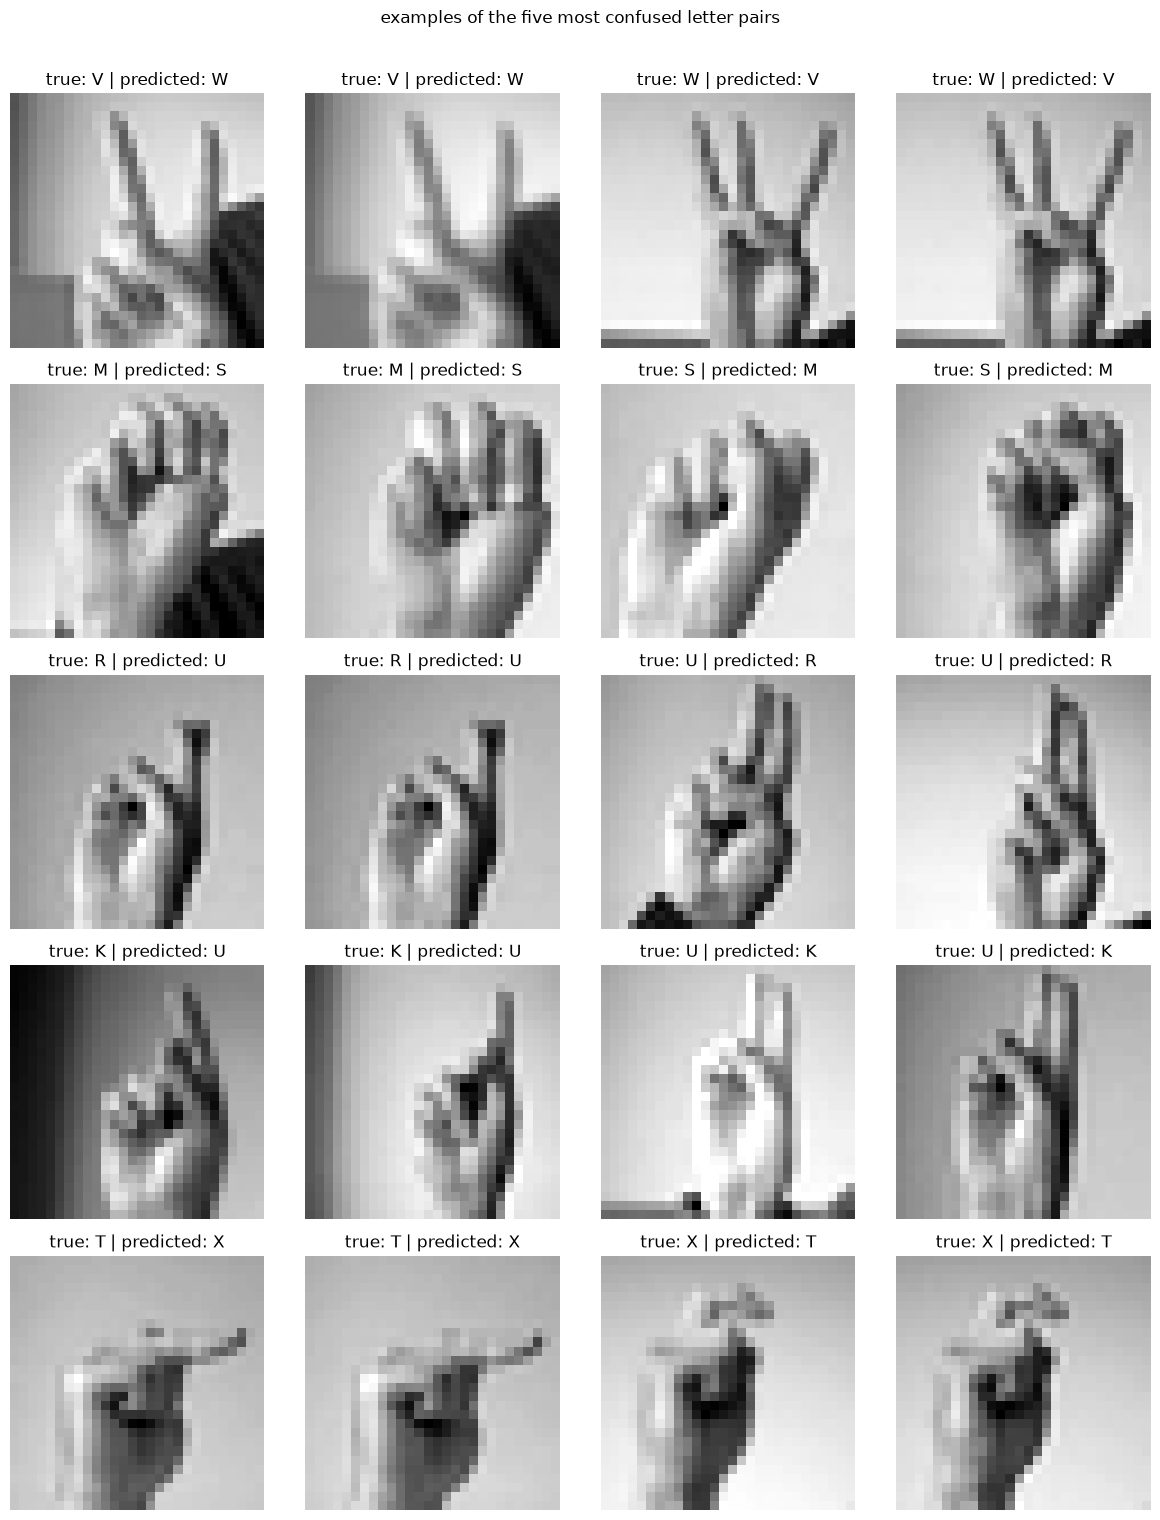

In [10]:
# create a mapping, from each letter to its numeric label
letter_to_label = {
    label_to_letter(label): label
    for label in unique_labels
}

# create a figure, with five rows and four columns
fig, axes = plt.subplots( 5 , 4 , figsize=(12,15) )

# go through the five most confused pairs
for row_index, (first_letter, second_letter, error_count) in enumerate(top_five_pairs):

    # get the numeric labels
    first_label = letter_to_label[first_letter]
    second_label = letter_to_label[second_letter]

    # find errors from the first letter to the second letter
    first_to_second_indices = np.where(
        (y_test == first_label) &
        (y_test_pred_final == second_label)
    )[0]

    # find errors from the second letter to the first letter
    second_to_first_indices = np.where(
        (y_test == second_label) &
        (y_test_pred_final == first_label)
    )[0]

    # show up to two examples, from the first direction
    for column_index in range(2):

        # get the current axis
        axis = axes[ row_index , column_index ]

        # check if an example is available
        if column_index < len(first_to_second_indices):

            # get the example index
            example_index = first_to_second_indices[column_index]

            # reshape the image
            image = x_test[example_index].reshape(28,28)

            # show the image
            axis.imshow( image , cmap="gray" )

            # write the true and predicted letters
            axis.set_title(
                "true: " + first_letter +
                " | predicted: " + second_letter
            )

        # hide the axis values
        axis.axis("off")

    # show up to two examples, from the second direction
    for column_index in range(2):

        # get the current axis
        axis = axes[ row_index , column_index + 2 ]

        # check if an example is available
        if column_index < len(second_to_first_indices):

            # get the example index
            example_index = second_to_first_indices[column_index]

            # reshape the image
            image = x_test[example_index].reshape(28,28)

            # show the image
            axis.imshow( image , cmap="gray" )

            # write the true and predicted letters
            axis.set_title(
                "true: " + second_letter +
                " | predicted: " + first_letter
            )

        # hide the axis values
        axis.axis("off")

# write the figure title
fig.suptitle( "examples of the five most confused letter pairs" , y=1.01 )

# adjust the figure spacing
plt.tight_layout()

# save the figure
plt.savefig(
    "../results/figures/stage1_top_confusion_examples.png" ,
    dpi=200 ,
    bbox_inches="tight"
)

# show the figure
plt.show()

### interpretation of the most confused letter pairs

the examples show that several of the largest confusion pairs have very similar
hand shapes.

V and W are visually similar because both signs use extended fingers with a
similar overall hand orientation.

M and S both have compact hand shapes, and the differences between them are
relatively local.

R and U were predicted before training to be difficult to distinguish.
the examples support this prediction, because the two signs have a similar
overall structure and differ mainly in the relative positions of the fingers.

K and U also share a similar upright hand structure, which can make them
difficult for a raw-pixel classifier when the hand position or orientation
changes.

T and X both contain a mostly closed hand with one prominent finger structure,
which can produce similar pixel patterns.

the examples also show that some images within the same confusion direction are
very similar to each other.

this is consistent with the dataset containing transformed near-copies of
original photographs.

overall, the confusion examples show that raw pixels are strongly affected by
both visual similarity and exact spatial arrangement.

## stage 1 result tables

the following tables summarize the main quantitative results of stage 1.

the first table shows the validation results for all tested values of C.

the official test set was evaluated only for the selected value C = 10, after
model selection was complete.

the second table shows the five most confused letter pairs on the official test set.

In [11]:
# create a dataframe, with the c validation results
c_results_table = pd.DataFrame(
    c_results ,
    columns=[ "C" , "validation accuracy" , "validation errors" ]
)

# convert the validation accuracy, to percentage text
c_results_table["validation accuracy (%)"] = c_results_table["validation accuracy"].apply(
    lambda value: f"{value * 100:.2f}%"
)

# remove the original decimal accuracy column
c_results_table = c_results_table.drop(
    columns=["validation accuracy"]
)

# create the test accuracy column, as text
c_results_table["test accuracy (%)"] = "-"

# create the test errors column, as text
c_results_table["test errors"] = "-"

# find the row, with the selected c value
selected_row = c_results_table["C"] == 10.0

# add the final test accuracy, only for the selected model
c_results_table.loc[
    selected_row ,
    "test accuracy (%)"
] = f"{final_test_accuracy * 100:.2f}%"

# add the final test errors, only for the selected model
c_results_table.loc[
    selected_row ,
    "test errors"
] = str(final_test_errors)

# reorder the columns
c_results_table = c_results_table[
    [
        "C" ,
        "validation accuracy (%)" ,
        "validation errors" ,
        "test accuracy (%)" ,
        "test errors"
    ]
]

# show the c results table
display(c_results_table)

# save the c results table, as a csv file
c_results_table.to_csv(
    "../results/tables/stage1_c_results.csv" ,
    index=False
)

# create a dataframe, with the five most confused letter pairs
confusion_table = pd.DataFrame(
    top_five_pairs ,
    columns=[ "first letter" , "second letter" , "total errors" ]
)

# show the confusion table
display(confusion_table)

# save the confusion table, as a csv file
confusion_table.to_csv(
    "../results/tables/stage1_top_confusions.csv" ,
    index=False
)

,C,validation accuracy (%),validation errors,test accuracy (%),test errors
0,0.001,61.66%,2105,-,-
1,0.010,83.28%,918,-,-
2,0.100,98.34%,91,-,-
3,1.000,99.96%,2,-,-
4,10.000,99.98%,1,69.27%,2204
5,100.000,99.84%,9,-,-
6,1000.000,99.82%,10,-,-


,first letter,second letter,total errors
0,V,W,113
1,M,S,111
2,R,U,104
3,K,U,82
4,T,X,82


### stage 1 summary

stage 1 investigated how well a softmax classifier can recognize static hand
signs directly from raw pixel values.

each image was represented by 784 normalized pixel features.

## data and validation setup

the official training set was divided into training and validation subsets using
a fixed random seed and stratification.

the same split will be reused in the later stages so that the results remain
directly comparable.

the official test set was not used during model selection.

## choosing C

i tested the following values of the regularization parameter C:

- 0.001
- 0.01
- 0.1
- 1
- 10
- 100
- 1000

the best validation result was obtained with:

C = 10

this model achieved:

- validation accuracy: 99.98%
- validation errors: 1

very small values of C performed much worse, which is consistent with excessive
regularization.

increasing C improved validation performance up to C = 10.

increasing C further to 100 and 1000 slightly reduced validation accuracy.

therefore, the prediction that an intermediate value of C would perform best
was supported.

## final test performance

after selecting C = 10 using only the validation set, i evaluated the selected
model on the official test set.

the final test result was:

- test accuracy: 69.27%
- test errors: 2204

this produced a very large gap between validation and test performance.

the random validation split was therefore highly optimistic.

one likely explanation is that the training data contains many transformed
near-copies of a smaller number of original photographs.

a random split can place very similar images in both the training and validation
sets, making the validation task easier than the official test set.

## learned weight patterns

i visualized the learned softmax weights for several letters as 28 by 28 images.

the weight maps show which fixed pixel locations provide positive or negative
evidence for each class.

this demonstrates that the raw-pixel classifier relies strongly on spatial pixel
positions.

as a result, changes in hand position, orientation or local structure can strongly
affect the classifier.

## confusion analysis

for each pair of letters, i combined the errors in both directions.

the five most confused letter pairs on the official test set were:

- V and W: 113 total errors
- M and S: 111 total errors
- R and U: 104 total errors
- K and U: 82 total errors
- T and X: 82 total errors

before training, i predicted that several visually similar pairs would be
difficult for the classifier.

## the prediction was partially supported.

R and U were included in my original prediction and also appeared among the five
most confused pairs.

other large confusion pairs, such as V and W, M and S, K and U, and T and X,
were not all predicted in advance.

the example images show that several of these pairs have similar hand shapes
and similar spatial pixel patterns.

## stage 1 conclusion

the softmax classifier can fit the randomly split training data extremely well,
but its official test performance is much lower.

the main limitation is not the classifier's ability to fit the validation data.

the main limitation is that raw pixels are sensitive to exact spatial position
and that the random validation split can give an overly optimistic estimate of
generalization.

stage 2 will test whether PCA can create a lower-dimensional linear feature
representation that removes some redundancy or noise while preserving useful
classification information.